In [41]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
DATA = Path("../data/processed/monthly_qc_dataset.csv")

df = pd.read_csv(DATA)

df['MONTH'] = pd.PeriodIndex(df['MONTH'], freq="M")

print("Shape:", df.shape)
print("Eligible rows:", df['ELIGIBLE_ALL_90'].sum())
print("Stations:", df['STATION'].nunique())


Shape: (2016, 32)
Eligible rows: 1926
Stations: 6


In [42]:
# creating new 3 features 
# 1- PRCP_LAG_0 = the current month percepitation t
# 2- PRCP_LAG_1 = last month percepitation t-1
# 3- PRCP_LAG_2 = the month before last percepitation t-2
# Target is next month percepitation t+1

feature_df = df.copy()
feature_df = feature_df.sort_values(['STATION','MONTH']).copy()

feature_df['PRCP_LAG_0'] = feature_df['PRCP_TOTAL']
feature_df['PRCP_LAG_1'] = (feature_df.groupby('STATION')['PRCP_TOTAL'].shift(1))
feature_df['PRCP_LAG_2'] = (feature_df.groupby('STATION')['PRCP_TOTAL'].shift(2))

display(feature_df[['STATION', 'MONTH', 'PRCP_TOTAL', 'PRCP_LAG_0',
                   'PRCP_LAG_1','PRCP_LAG_2', 'TARGET_NEXT_MONTH']].head(8))

,STATION,MONTH,PRCP_TOTAL,PRCP_LAG_0,PRCP_LAG_1,PRCP_LAG_2,TARGET_NEXT_MONTH
0,41184099999,1996-01,0.0,0.0,NaN,NaN,0.0
1,41184099999,1996-02,0.0,0.0,0.0,NaN,0.0
2,41184099999,1996-03,0.0,0.0,0.0,0.0,0.0
3,41184099999,1996-04,0.0,0.0,0.0,0.0,0.0
4,41184099999,1996-05,0.0,0.0,0.0,0.0,0.0
5,41184099999,1996-06,0.0,0.0,0.0,0.0,0.0
6,41184099999,1996-07,0.0,0.0,0.0,0.0,0.0
7,41184099999,1996-08,0.0,0.0,0.0,0.0,0.0


In [43]:


feature_df["PRCP_QC_LAG_0"] = (
    feature_df["PRCP_COMPLETENESS"]
)

feature_df["PRCP_QC_LAG_1"] = (
    feature_df.groupby("STATION")["PRCP_COMPLETENESS"]
    .shift(1)
)

feature_df["PRCP_QC_LAG_2"] = (
    feature_df.groupby("STATION")["PRCP_COMPLETENESS"]
    .shift(2)
)

display(
    feature_df[
        ["STATION", "MONTH",
         "PRCP_LAG_0", "PRCP_QC_LAG_0",
         "PRCP_LAG_1", "PRCP_QC_LAG_1",
         "PRCP_LAG_2", "PRCP_QC_LAG_2"]
    ].head(5)
)


,STATION,MONTH,PRCP_LAG_0,PRCP_QC_LAG_0,PRCP_LAG_1,PRCP_QC_LAG_1,PRCP_LAG_2,PRCP_QC_LAG_2
0,41184099999,1996-01,0.0,93.548387,NaN,NaN,NaN,NaN
1,41184099999,1996-02,0.0,93.103448,0.0,93.548387,NaN,NaN
2,41184099999,1996-03,0.0,90.322581,0.0,93.103448,0.0,93.548387
3,41184099999,1996-04,0.0,100.000000,0.0,90.322581,0.0,93.103448
4,41184099999,1996-05,0.0,100.000000,0.0,100.000000,0.0,90.322581


In [44]:

lag_qc_columns = [
    "PRCP_QC_LAG_0",
    "PRCP_QC_LAG_1",
    "PRCP_QC_LAG_2"
]


feature_df["LAG_QC_90"] = (
    feature_df[lag_qc_columns]
    .ge(90)
    .all(axis=1)
)

feature_df["ELIGIBLE_B_90"] = (
    feature_df["ELIGIBLE_ALL_90"]
    & feature_df["LAG_QC_90"]
)

print("Feature Set A eligible:",
      feature_df["ELIGIBLE_ALL_90"].sum())

print("Feature Set B eligible:",
      feature_df["ELIGIBLE_B_90"].sum())

print("Additional rows excluded:",
      feature_df["ELIGIBLE_ALL_90"].sum()
      - feature_df["ELIGIBLE_B_90"].sum())


Feature Set A eligible: 1926
Feature Set B eligible: 1768
Additional rows excluded: 158


In [45]:
comparison_df = feature_df[feature_df['ELIGIBLE_B_90']].copy()

# Feature Set A 
features_A = [
    'TEMP_MEAN',
    'DEWP_MEAN',
    'WDSP_MEAN',
    'TEMP_MIN_MEAN',
    'TEMP_MAX_MEAN'
]

features_B = features_A + [
    'PRCP_LAG_0',
    'PRCP_LAG_1',
    'PRCP_LAG_2'
]

X_A = comparison_df[features_A].copy()
X_B = comparison_df[features_B].copy()
y = comparison_df['TARGET_NEXT_MONTH'].copy()

print("Shape X_A", X_A.shape)
print("Shape X_B", X_B.shape)
print("Shape y", y.shape)

print("Missing values in A:", X_A.isna().sum().sum())
print("Missing values in B:", X_B.isna().sum().sum())
print("Missing values in y:", y.isna().sum())



Shape X_A (1768, 5)
Shape X_B (1768, 8)
Shape y (1768,)
Missing values in A: 0
Missing values in B: 0
Missing values in y: 0


In [46]:
metadata = comparison_df[['STATION','MONTH']].copy()

metadata['TARGET_MONTH'] = (metadata['MONTH'] + 1)
duplicates = metadata.duplicated(subset=['STATION','MONTH']).sum()
print("Duplicate station-month rows:", duplicates)

ordered = comparison_df.sort_values(['STATION','MONTH'])
print("Ordered:",comparison_df.index.equals(ordered.index))
display(metadata.head())

Duplicate station-month rows: 0
Ordered: True


,STATION,MONTH,TARGET_MONTH
2,41184099999,1996-03,1996-04
3,41184099999,1996-04,1996-05
4,41184099999,1996-05,1996-06
5,41184099999,1996-06,1996-07
6,41184099999,1996-07,1996-08


In [47]:
# TARGET_NEXT_MONTH = PRCP_TOTAL verification

actual_rainfall = feature_df[['STATION','MONTH','PRCP_TOTAL']].copy()
actual_rainfall = actual_rainfall.rename(
    columns={
        'MONTH': 'TARGET_MONTH',
        'PRCP_TOTAL': 'ACTUAL_NEXT_MONTH'
    }
)

verification = metadata.merge(
    actual_rainfall, on=['STATION','TARGET_MONTH'], how="left", validate='one_to_one' 
)
verification = verification.merge(
    comparison_df[['STATION','MONTH','TARGET_NEXT_MONTH']],
    on=["STATION","MONTH"],
    how='left',
    validate='one_to_one'
)

verification['DIFFERENCE']=(verification['TARGET_NEXT_MONTH'] - verification['ACTUAL_NEXT_MONTH']).abs()

print("Max difference:", verification['DIFFERENCE'].max())
print("Mismatched row:", (verification['DIFFERENCE'] > 1e-9).sum())
print("Missing actual targets:", verification["ACTUAL_NEXT_MONTH"].isna().sum())
display(verification.head())

Max difference: 0.0
Mismatched row: 0
Missing actual targets: 0


,STATION,MONTH,TARGET_MONTH,ACTUAL_NEXT_MONTH,TARGET_NEXT_MONTH,DIFFERENCE
0,41184099999,1996-03,1996-04,0.0,0.0,0.0
1,41184099999,1996-04,1996-05,0.0,0.0,0.0
2,41184099999,1996-05,1996-06,0.0,0.0,0.0
3,41184099999,1996-06,1996-07,0.0,0.0,0.0
4,41184099999,1996-07,1996-08,0.0,0.0,0.0


,FOLD,TEST_STATION,TRAIN_STATIONS,TEST_STATIONS,TRAIN_ROWS,TEST_ROWS
0,1,41184099999,5,1,1471,297
1,2,41194099999,5,1,1455,313
2,3,41196099999,5,1,1473,295
3,4,41198099999,5,1,1496,272
4,5,41217099999,5,1,1466,302
5,6,41218099999,5,1,1479,289


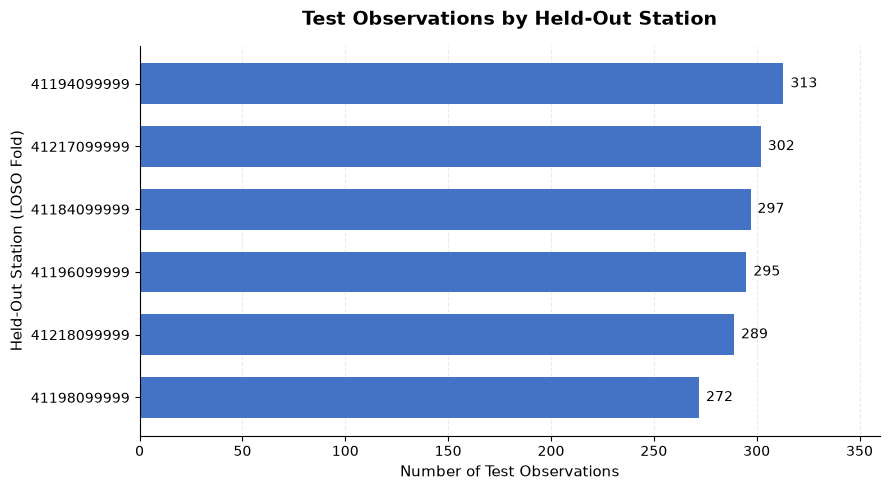

In [54]:
# Model Evaluation Design 
# Manual LOSO Cross-Validation

stations = sorted(comparison_df['STATION'].unique())

fold_results = []

for fold, test_station in enumerate(stations, start=1):
    train_mask = comparison_df['STATION'] != test_station
    test_mask = comparison_df['STATION'] == test_station
    train_df, test_df = comparison_df[train_mask].copy(), comparison_df[test_mask].copy()
    train_stations, test_stations = set(train_df['STATION'].unique()), set(test_df['STATION'].unique())

    fold_results.append({
        'FOLD': fold,
        'TEST_STATION': test_station,
        'TRAIN_STATIONS': len(train_stations),
        'TEST_STATIONS': len(test_stations),
        'TRAIN_ROWS': len(train_df),
        "TEST_ROWS": len(test_df)
    })

fold_summary = pd.DataFrame(fold_results)
display(fold_summary)


plot_df = fold_summary.sort_values("TEST_ROWS", ascending=True)

fig, ax = plt.subplots(figsize=(9,5))

bars = ax.barh(
    plot_df['TEST_STATION'].astype(str),
    plot_df['TEST_ROWS'],
    color='#4472C4',
    height=0.65
)

ax.bar_label(
    bars,
    labels=[f'{n:,}' for n in plot_df['TEST_ROWS']],
    padding=5,
    fontsize=10
)

ax.set_title(
    'Test Observations by Held-Out Station',
    fontsize=14,
    fontweight='bold',
    pad=15
)
ax.set_xlabel('Number of Test Observations', fontsize=11)
ax.set_ylabel('Held-Out Station (LOSO Fold)', fontsize=11)

# Clean formatting
ax.set_axisbelow(True)
ax.grid(axis='x', linestyle='--', alpha=0.25)
ax.spines[['top', 'right']].set_visible(False)
ax.margins(x=0.15)

plt.tight_layout()
plt.show()

In [61]:
test_indices = []
stations = sorted(comparison_df['STATION'].unique())

for test_station in stations:
    test_mask = (comparison_df['STATION'] == test_station)
    fold_test_indices = comparison_df[test_mask].index.tolist()
    test_indices.extend(fold_test_indices)

total_test_appearances = len(test_indices)
unique_test_observations = len(set(test_indices))

print("Total test appearances:", total_test_appearances)
print("Unique test observations:", unique_test_observations)
print("Expected observations:", len(comparison_df))


Total test appearances: 1768
Unique test observations: 1768
Expected observations: 1768
